# 02 · Parkings d'Auvergne-Rhône-Alpes

**Objectif** : recenser les parkings de la région avec, quand il est connu, leur **nombre de places**, leur type et leurs conditions d'accès. Un parking public proche est un emplacement possible pour une station Citiz, et sa capacité indique la place disponible.

**Sources** :

- **OpenStreetMap** (`amenity=parking`), toute la région, via l'API Overpass, licence ODbL. C'est la source la plus complète, mais le nombre de places (`capacity`) n'est renseigné que pour une partie des parkings.
- **Base nationale des lieux de stationnement (BNLS)**, transport.data.gouv.fr, Licence Ouverte. Parkings hors voirie déclarés par les collectivités et opérateurs, avec places, tarifs et places d'autopartage. Elle n'est **pas exhaustive** : quelques centaines de parkings seulement pour la région.

Le tableau `regional-data/data/processed/osm_aura_table.csv` contient déjà les parkings OSM, mais sans leurs attributs (`capacity`, `parking`, `fee`…) : il faut donc les relire depuis OSM.

In [1]:
import json
import re
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(d for d in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (d / "siting-data" / "siting_sources.py").is_file())
sys.path.insert(0, str(ROOT / "siting-data"))
from siting_sources import (AURA_DEPARTMENTS, assign_department, download, fetch_overpass, load_departments,
                            load_region, module_paths)

ROOT, RAW, CLEAN = module_paths()
region = load_region()
departments = load_departments()

## 1. Télécharger les parkings OSM

**Overpass** est une API de lecture d'OpenStreetMap. La requête sélectionne la zone administrative `FR-ARA` (code ISO de la région), puis tous les objets `amenity=parking` :

- `nwr` signifie *node, way, relation* : un parking peut être un point, un contour (way) ou un multipolygone (relation) ;
- `out center tags` renvoie, pour les contours, leur **centre** au lieu de toute la géométrie, ainsi que tous les attributs OSM.

La réponse est conservée dans `data/raw/` avec sa date (`osm3s.timestamp_osm_base`) : relancer le notebook réutilise cette copie.

In [2]:
OVERPASS_QUERY = '''
[out:json][timeout:900];
area["ISO3166-2"="FR-ARA"]->.region;
nwr["amenity"="parking"](area.region);
out center tags;
'''
payload = fetch_overpass(OVERPASS_QUERY, RAW / "osm_parking_aura.json", description="OSM amenity=parking AURA")
OSM_SNAPSHOT = payload["osm3s"]["timestamp_osm_base"]
elements = payload["elements"]
print(f"OSM snapshot: {OSM_SNAPSHOT}; {len(elements)} parking objects")

OSM snapshot: 2026-10-20T13:01:15Z; 87003 parking objects


## 2. Mettre les objets OSM à plat

Une ligne par parking, identifiée par `osm_uid` (`node/123`, `way/456`…), comme dans `regional-data/`. Pour un point on prend sa position, pour un contour son centre. On garde les attributs utiles ; `tags_json` conserve tous les autres.

In [3]:
KEPT_TAGS = ["name", "parking", "access", "fee", "capacity", "capacity:disabled", "capacity:charging",
             "park_ride", "operator", "surface", "maxstay", "opening_hours", "covered"]

def flatten(element):
    tags = element.get("tags", {})
    position = element if element["type"] == "node" else element.get("center", {})
    row = {"osm_uid": f"{element['type']}/{element['id']}", "osm_type": element["type"],
           "lon": position.get("lon"), "lat": position.get("lat")}
    row.update({tag: tags.get(tag) for tag in KEPT_TAGS})
    row["tags_json"] = json.dumps(tags, ensure_ascii=False, sort_keys=True)
    return row

osm = pd.DataFrame([flatten(e) for e in elements])
print(osm["osm_type"].value_counts().to_dict(), "| missing position:", osm[["lon", "lat"]].isna().any(axis=1).sum())
assert osm["osm_uid"].is_unique
display(osm[KEPT_TAGS].notna().sum().rename("objects with tag").to_frame())

{'way': 82181, 'node': 4484, 'relation': 338} | missing position: 0


,objects with tag
name,6035
parking,58591
access,39801
fee,26465
capacity,19758
capacity:disabled,10094
capacity:charging,114
park_ride,2736
operator,2106
surface,20791


## 3. Nettoyer le nombre de places

`capacity` est un texte libre dans OSM. On l'examine avant de le convertir : certaines valeurs ne sont pas des nombres (`yes`, `~50`, `10-20`, `20;5`).

Règle retenue : seul un **entier positif écrit seul** est accepté. Toute autre valeur devient **inconnue** (cellule vide) et reste lisible dans `capacity_raw`. Une capacité nulle ou absente n'est jamais remplacée par zéro.

In [4]:
raw_capacity = osm["capacity"].dropna()
non_numeric = raw_capacity[~raw_capacity.str.fullmatch(r"\s*\d+\s*")]
print(f"capacity filled: {len(raw_capacity)}, not a plain integer: {len(non_numeric)}")
non_numeric.value_counts().head(20)

capacity filled: 19758, not a plain integer: 20


capacity
12Privé                                                                                                                                                                                                                                                           2
40;37                                                                                                                                                                                                                                                             1
15-20                                                                                                                                                                                                                                                             1
650 places en été, 150 places en Hiver                                                                                                                                                                             

In [5]:
def parse_count(value):
    """Return a positive integer written alone, otherwise missing."""
    if value is None or pd.isna(value):
        return pd.NA
    text = str(value).strip()
    if not re.fullmatch(r"\d+", text) or int(text) == 0:
        return pd.NA
    return int(text)

osm["capacity_raw"] = osm["capacity"]
for column in ["capacity", "capacity:disabled", "capacity:charging"]:
    osm[column] = osm[column].map(parse_count).astype("Int64")
display(osm["capacity"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame())
osm.nlargest(10, "capacity")[["osm_uid", "name", "parking", "capacity"]]

,capacity
count,19714.0
mean,21.66151
std,71.313294
min,1.0
50%,7.0
90%,40.0
99%,284.74
max,3200.0


,osm_uid,name,parking,capacity
18505,way/310360085,Parking Evenementiel des Panettes,surface,3200
8542,way/138890718,NaN,surface,2000
3981,node/13188486114,LPA Villette P2,underground,1773
29276,way/591245203,P1,multi-storey,1700
31024,way/646573387,Parking Confluence,multi-storey,1500
61039,way/1252550211,NaN,surface,1410
9570,way/160401870,Grand'Place Nord,multi-storey,1400
9584,way/161025359,NaN,surface,1364
20181,way/357188356,NaN,surface,1300
3807,node/12696418803,Parc LPA Béraudier P1,underground,1254


Les plus grandes capacités correspondent à des parkings de stations de ski, de centres commerciaux ou d'aéroport : elles sont plausibles et conservées. Un seuil de contrôle (`capacity_suspect`) signale les valeurs au-delà de 5 000 places, à vérifier avant usage.

## 4. Harmoniser le type de parking et l'accès

- `parking_type` : valeur OSM `parking` (`surface`, `underground`, `multi-storey`, `street_side`, `lane`…) ; absente → `unknown`.
- `access_class` regroupe la valeur `access` en quatre classes :
  - `public` : `yes`, `permissive`, `public`, `destination` ;
  - `customers` : réservé aux clients d'un commerce ou d'un service ;
  - `private` : `private`, `no`, `residents`, `permit`, `employees`, `delivery`… ;
  - `subscribers` (BNLS uniquement) : réservé aux abonnés ;
  - `unknown` : accès non renseigné. Dans OSM, l'absence d'`access` signifie souvent « public », mais ce n'est pas garanti : on ne le présume pas.
- `fee` : `yes` / `no` / `unknown`.

In [6]:
ACCESS_CLASSES = {
    "public": {"yes", "permissive", "public", "destination", "designated"},
    "customers": {"customers", "customer", "visitors", "guests"},
    "private": {"private", "no", "residents", "permit", "employees", "staff", "delivery", "agricultural",
                "forestry", "military", "emergency", "disabled", "official", "members"},
}

def access_class(value):
    if value is None or pd.isna(value):
        return "unknown"
    first = str(value).split(";")[0].strip().lower()
    return next((name for name, values in ACCESS_CLASSES.items() if first in values), "other")

def yes_no(value):
    if value is None or pd.isna(value):
        return "unknown"
    value = str(value).strip().lower()
    return value if value in {"yes", "no"} else "other"

osm["parking_type"] = osm["parking"].fillna("unknown")
osm["access_class"] = osm["access"].map(access_class)
osm["fee"] = osm["fee"].map(yes_no)
osm["park_ride"] = osm["park_ride"].map(lambda v: "unknown" if v is None or pd.isna(v) else ("no" if v == "no" else "yes"))
display(osm["access_class"].value_counts().to_frame())
display(osm["parking_type"].value_counts().head(12).to_frame())
osm.loc[osm["access_class"] == "other", "access"].value_counts().head(10)

,count
access_class,
unknown,47202
public,20558
private,12964
customers,6233
other,46


,count
parking_type,
surface,40116
unknown,28412
street_side,15335
lane,2070
underground,392
multi-storey,379
layby,119
rooftop,64
garage_boxes,34


access
hgv           17
unknown       16
restricted     6
psv            3
students       1
bus            1
charging       1
service        1
Name: count, dtype: int64

## 5. Garder les parkings situés dans la région

La zone `FR-ARA` d'OSM et le contour IGN ne coïncident pas exactement. On garde les parkings dont la position est **dans le contour IGN** ; on note combien sont écartés. On rattache aussi chaque parking à son département par jointure spatiale (*point dans polygone*).

In [7]:
osm_points = gpd.GeoDataFrame(osm, geometry=gpd.points_from_xy(osm["lon"], osm["lat"]), crs=4326)
inside = osm_points.within(region)
print(f"Outside the IGN outline: {(~inside).sum()} of {len(osm_points)}")
osm_points = osm_points.loc[inside].copy()
osm_points = assign_department(osm_points, departments)
osm_points["department_method"].value_counts(dropna=False)

Outside the IGN outline: 9 of 87003


department_method
within     86862
nearest      132
Name: count, dtype: int64

Les contours départementaux sont **simplifiés** : un parking très proche d'une limite peut ne tomber dans aucun département. Il est alors rattaché au département le plus proche, à 2 km au plus (`department_method = nearest`).

## 6. Base nationale des lieux de stationnement (BNLS)

Fichier consolidé `bnls-v2` publié sur data.gouv.fr. Séparateur `;`. Le code INSEE donne le département. Les nombres sont convertis avec la même règle que pour OSM (les zéros de la BNLS, par exemple `nb_autopartage = 0`, sont des **déclarations** et sont conservés pour ces colonnes de détail ; seul `nb_places = 0` est traité comme inconnu).

In [8]:
BNLS_URL = ("https://static.data.gouv.fr/resources/base-nationale-des-lieux-de-stationnement/"
            "20240109-111856/base-nationale-des-lieux-de-stationnement-outil-de-consolidation-bnls-v2.csv")
bnls_raw = pd.read_csv(download(BNLS_URL, RAW / "bnls_v2.csv", description="BNLS v2 consolidation"), sep=";", dtype=str)
bnls = bnls_raw.loc[bnls_raw["insee"].str[:2].isin(AURA_DEPARTMENTS)].copy()
print(f"BNLS France: {len(bnls_raw)} rows; AURA: {len(bnls)} rows")
print("duplicated id:", bnls["id"].duplicated().sum(), "| missing coordinates:", bnls[["Xlong", "Ylat"]].isna().any(axis=1).sum())

def to_number(series):
    return pd.to_numeric(series.str.replace(",", ".", regex=False), errors="coerce")

bnls["lon"], bnls["lat"] = to_number(bnls["Xlong"]), to_number(bnls["Ylat"])
bnls["capacity"] = bnls["nb_places"].map(parse_count).astype("Int64")
for column in ["nb_pmr", "nb_voitures_electriques", "nb_autopartage", "nb_velo"]:
    bnls[column] = to_number(bnls[column]).astype("Int64")
bnls["tarif_1h"] = to_number(bnls["tarif_1h"])
bnls_points = gpd.GeoDataFrame(bnls, geometry=gpd.points_from_xy(bnls["lon"], bnls["lat"]), crs=4326)
print("BNLS outside IGN outline:", (~bnls_points.within(region)).sum())
display(bnls["insee"].str[:2].value_counts().rename("parkings").to_frame())
bnls[["id", "nom", "insee", "capacity", "nb_autopartage", "type_ouvrage", "gratuit", "tarif_1h"]].head()

BNLS France: 826 rows; AURA: 239 rows
duplicated id: 0 | missing coordinates: 0


BNLS outside IGN outline: 0


,parkings
insee,
69,156
38,66
73,16
74,1


,id,nom,insee,capacity,nb_autopartage,type_ouvrage,gratuit,tarif_1h
120,38006-P-001,ALLEVARD PLACE DE VERDUN,38006,12,<NA>,enclos_en_surface,1,0.0
121,38039-P-001,BERNIN CLOYÈRES,38039,22,<NA>,enclos_en_surface,1,0.0
122,38059-P-001,BRIÉ ET ANGONNES - TAVERNOLLES,38059,36,<NA>,enclos_en_surface,1,0.0
123,38133-P-001,PLAN MENU,38133,150,<NA>,enclos_en_surface,1,NaN
124,38140-P-001,CROLLES RAFOUR,38140,41,<NA>,enclos_en_surface,1,0.0


## 7. Rapprocher BNLS et OSM

Un même parking peut figurer dans les deux sources. On cherche, pour chaque parking BNLS, le parking OSM **le plus proche à moins de 100 m**. Les distances sont calculées en mètres dans la projection Lambert-93 (EPSG:2154), la projection officielle de la France métropolitaine.

- S'il y a un parking OSM proche, la ligne BNLS est marquée `countable = False` et `duplicate_of` pointe vers lui ; ses informations (places, tarif, autopartage) sont reportées sur la ligne OSM.
- Sinon, la ligne BNLS reste une ligne à part entière.

Le rapprochement par distance peut se tromper quand plusieurs parkings sont voisins : la distance est conservée (`bnls_match_distance_m`) pour vérification.

In [9]:
MATCH_DISTANCE_M = 100
osm_metric = osm_points.to_crs(2154)
bnls_metric = bnls_points.to_crs(2154)[["id", "geometry"]]
matches = gpd.sjoin_nearest(bnls_metric, osm_metric[["osm_uid", "geometry"]], how="left",
                            max_distance=MATCH_DISTANCE_M, distance_col="distance_m")
matches = matches.sort_values("distance_m").drop_duplicates("id")       # one OSM parking per BNLS id
matches = matches.dropna(subset=["osm_uid"]).drop_duplicates("osm_uid")  # one BNLS id per OSM parking
print(f"BNLS parkings matched to OSM within {MATCH_DISTANCE_M} m: {len(matches)} / {len(bnls)}")
matches["distance_m"].describe()

BNLS parkings matched to OSM within 100 m: 165 / 239


count    165.000000
mean      44.566656
std       27.161489
min        1.690717
25%       20.649494
50%       41.843146
75%       64.675137
max       99.899156
Name: distance_m, dtype: float64

## 8. Construire la table unifiée

Une ligne par parking, avec :

- `parking_uid` : `osm:way/123` ou `bnls:<id>` ;
- `capacity` : nombre de places de la source de la ligne ; `capacity_best` : capacité OSM, ou à défaut celle de la BNLS rapprochée, avec `capacity_source` ;
- `countable` : `False` pour les lignes BNLS en double d'un parking OSM, à exclure des comptages.

In [10]:
bnls_info = bnls.set_index("id")[["capacity", "nb_autopartage", "gratuit", "tarif_1h", "type_ouvrage"]]
matched = matches.set_index("osm_uid")[["id", "distance_m"]].rename(columns={"id": "bnls_id", "distance_m": "bnls_match_distance_m"})

osm_table = osm_points.drop(columns="geometry").merge(matched, left_on="osm_uid", right_index=True, how="left")
osm_table = osm_table.merge(bnls_info.add_prefix("bnls_"), left_on="bnls_id", right_index=True, how="left")
osm_table = osm_table.assign(
    parking_uid="osm:" + osm_table["osm_uid"], source="osm", countable=True, duplicate_of=pd.NA,
    insee_code=pd.NA, carsharing_spaces=osm_table["bnls_nb_autopartage"], fee_1h_eur=osm_table["bnls_tarif_1h"],
    capacity_best=osm_table["capacity"].fillna(osm_table["bnls_capacity"]),
    capacity_source=osm_table["capacity"].notna().map({True: "osm"}).fillna(
        osm_table["bnls_capacity"].notna().map({True: "bnls"})),
)

bnls_table = bnls_points.drop(columns="geometry").merge(departments.drop(columns="geometry"),
    left_on=bnls_points["insee"].str[:2], right_on="department_code", how="left")
duplicate_of = matches.set_index("id")["osm_uid"]
bnls_table = bnls_table.assign(
    parking_uid="bnls:" + bnls_table["id"], source="bnls", osm_uid=pd.NA, name=bnls_table["nom"],
    insee_code=bnls_table["insee"], parking_type=bnls_table["type_ouvrage"].fillna("unknown"),
    access_class=bnls_table["type_usagers"].map({"tous": "public", "abonnés": "subscribers"}).fillna("unknown"),
    fee=bnls_table["gratuit"].map({"1": "no", "0": "yes"}).fillna("unknown"), park_ride=to_number(bnls_table["nb_pr"]).map(lambda n: "unknown" if pd.isna(n) else ("yes" if n > 0 else "no")),
    department_method="insee_code",
    duplicate_of=("osm:" + bnls_table["id"].map(duplicate_of)).where(bnls_table["id"].isin(duplicate_of.index)),
    countable=~bnls_table["id"].isin(duplicate_of.index), carsharing_spaces=bnls_table["nb_autopartage"],
    fee_1h_eur=bnls_table["tarif_1h"], capacity_best=bnls_table["capacity"],
    capacity_source=bnls_table["capacity"].notna().map({True: "bnls"}), capacity_raw=bnls_table["nb_places"],
    **{"capacity:disabled": bnls_table["nb_pmr"], "capacity:charging": bnls_table["nb_voitures_electriques"]},
)

COLUMNS = ["parking_uid", "source", "osm_uid", "bnls_id", "name", "parking_type", "access_class", "fee",
           "fee_1h_eur", "park_ride", "capacity", "capacity_best", "capacity_source", "capacity_raw",
           "capacity:disabled", "capacity:charging", "carsharing_spaces", "operator", "insee_code",
           "department_code", "department_name", "department_method", "lon", "lat", "countable", "duplicate_of", "bnls_match_distance_m"]
bnls_table["bnls_id"] = bnls_table["id"]
parking = pd.concat([osm_table.reindex(columns=COLUMNS), bnls_table.reindex(columns=COLUMNS)], ignore_index=True)
parking = parking.rename(columns={"capacity:disabled": "capacity_disabled", "capacity:charging": "capacity_charging"})
for column in ["capacity", "capacity_best", "capacity_disabled", "capacity_charging", "carsharing_spaces"]:
    parking[column] = parking[column].astype("Int64")
parking["capacity_suspect"] = (parking["capacity_best"] > 5000).fillna(False).astype(bool)
parking["osm_snapshot_utc"] = OSM_SNAPSHOT
assert parking["parking_uid"].is_unique
print(parking["source"].value_counts().to_dict(), "| countable:", int(parking["countable"].sum()))

{'osm': 86994, 'bnls': 239} | countable: 87068


## 9. Chiffres clés

Le total de places n'est **pas** le nombre réel de places de la région : c'est la somme des capacités **connues**. Le taux de capacité connue est affiché à côté pour ne pas l'oublier.

In [11]:
countable = parking.loc[parking["countable"]]
summary = countable.groupby(["department_code", "department_name"], dropna=False).agg(
    parkings=("parking_uid", "size"),
    public=("access_class", lambda s: (s == "public").sum()),
    with_capacity=("capacity_best", "count"),
    known_spaces=("capacity_best", "sum"),
    park_and_ride=("park_ride", lambda s: (s == "yes").sum()),
)
summary["capacity_known_pct"] = (100 * summary["with_capacity"] / summary["parkings"]).round(1)
display(summary)
print("Countable parkings:", len(countable), "| known spaces:", int(countable["capacity_best"].sum()),
      "| capacity known:", f"{100 * countable['capacity_best'].notna().mean():.1f} %",
      "| suspect capacities:", int(countable["capacity_suspect"].sum()))

,,parkings,public,with_capacity,known_spaces,park_and_ride,capacity_known_pct
department_code,department_name,,,,,,
01,Ain,5839,1282,1244,20521,46,21.3
03,Allier,3183,572,582,21711,27,18.3
07,Ardèche,3223,984,605,10486,4,18.8
15,Cantal,1369,358,150,2877,22,11.0
26,Drôme,7246,2336,2333,30964,37,32.2
38,Isère,19240,4475,6510,112665,124,33.8
42,Loire,5494,1651,1407,27032,32,25.6
43,Haute-Loire,1663,319,246,5790,17,14.8
63,Puy-de-Dôme,7147,1327,786,28978,64,11.0


Countable parkings: 87068 | known spaces: 443502 | capacity known: 22.8 % | suspect capacities: 0


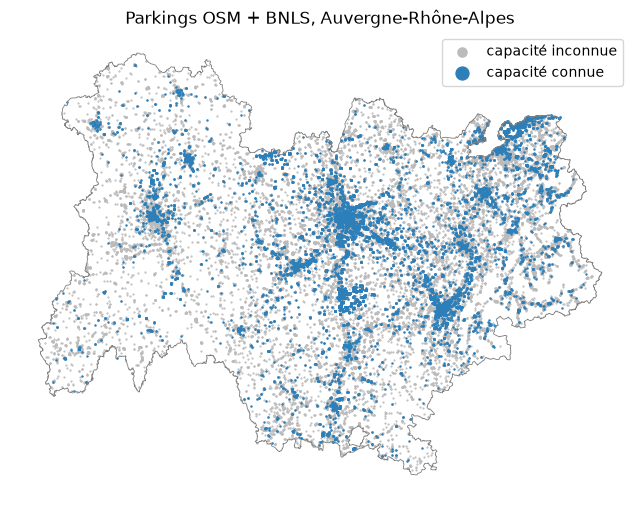

In [12]:
fig, ax = plt.subplots(figsize=(8, 8))
gpd.GeoSeries([region], crs=4326).boundary.plot(ax=ax, color="grey", linewidth=0.6)
known = countable.loc[countable["capacity_best"].notna()]
unknown = countable.loc[countable["capacity_best"].isna()]
ax.scatter(unknown["lon"], unknown["lat"], s=0.3, color="#bbbbbb", label="capacité inconnue")
ax.scatter(known["lon"], known["lat"], s=0.6, color="#2c7fb8", label="capacité connue")
ax.set_title("Parkings OSM + BNLS, Auvergne-Rhône-Alpes")
ax.legend(markerscale=12)
ax.set_axis_off()
plt.show()

## 10. Export et relecture

In [13]:
output_path = CLEAN / "parking_aura.csv"
parking.to_csv(output_path, index=False)
reread = pd.read_csv(output_path, dtype={"insee_code": str, "department_code": str, "bnls_id": str}, low_memory=False)
assert len(reread) == len(parking) and reread["parking_uid"].is_unique
assert reread["capacity_best"].isna().sum() == parking["capacity_best"].isna().sum()
assert (reread["capacity_best"].dropna() > 0).all()
print(f"Wrote {output_path.relative_to(ROOT)}: {len(reread)} rows, {reread.shape[1]} columns")

Wrote siting-data/data/clean/parking_aura.csv: 87233 rows, 29 columns
